# Pipeline Deteksi Lokasi + Klasifikasi impacted/erupted Molar III Bawah
### ExAn-MTM (973 OPG) — YOLO11n (deteksi) + klasifikasi crop (feature & CNN)

**Tujuan.** Menghasilkan pipeline reproducible yang (1) mendeteksi *lokasi* molar ketiga bawah pada panoramik
dan (2) mengklasifikasikan tiap kandidat-region sebagai *impacted* (i-MTM) atau *erupted* (e-MTM).
Pipeline ini sengaja designed modular: tahap klasifikasi_crop adalah titik sambung untuk
klasifikasi lanjutan (mis. Winter/angulasi 6 kelas) ketika dataset angulasi resmi sudah tersedia.

**Dataset.** *Expert Annotated Mandibular Third Molar (ExAn-MTM) Dataset*, Mendeley Data
DOI `10.17632/t8k59p35p6.1`, lisensi **CC BY-NC-ND 4.0** (Kayadibi et al., 2025).
973 citra OPG beranotasi bounding box YOLO; split resmi train 875 / valid 98.
Kelas: `0 = e-MTM` (erupted), `1 = i-MTM` (impacted).

**Rujukan metode.**
1. Kayadibi, I. et al. (2025). *E-MTMYOLO: An Explainable YOLOv5-Based Deep Learning Model for
   Multi-Class Mandibular Third Molar Classification and Localization on Panoramic X-Rays.*
   The Journal of Supercomputing, 81, 1286. https://doi.org/10.1007/s11227-025-07775-w
2. Khurshid, S. et al. (2026). *Dual framework for classification and detection of third molar impaction in panoramic radiographs.*
   International Dental Journal, 76(1), 109430. https://doi.org/10.1016/j.identj.2026.109430

**Cara menjalankan.**
```bash
uv venv --python 3.12 .venv
uv pip install --python .venv/Scripts/python.exe torch torchvision --index-url https://download.pytorch.org/whl/cpu
uv pip install --python .venv/Scripts/python.exe ultralytics jupyter nbconvert ipykernel matplotlib pandas scikit-learn opencv-python seaborn pillow
.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace \
  Pipeline/PCVK_Pipeline_Deteksi_Klasifikasi_Impaksi.ipynb --ExecutePreprocessor.timeout=5400
```
Semua keluaran numerik ditulis ke `Pipeline/outputs/` (`metrics.json`, `figures/`, `runs/`, `crops/`, `annotated/`).

> **Catatan etika.** Angka di notebook ini adalah hasil eksperimen pada data publik; bukan klaim klinis
> dan bukan performa alat diagnostik. Dataset berlisensi NC-ND: **tidak** boleh diunggah ulang ke repo publik
> dan tidak boleh dimodifikasi untuk distribusi ulang.

In [1]:
# === 1. SETUP: environment, seed, path, konfigurasi ekperimen ====================
import os, sys, json, glob, time, random, shutil, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 2))

ROOT = Path(r"C:/Kuliah/Tingkat 3/PCVK/Project")
EXAN = ROOT / "Datasets" / "Expert Annotated Mandibular Third Molar (ExAn-MTM)" / \
       "Expert Annotated Mandibular Third Molar (ExAn-MTM)" / "ExAn-MTM dataset" / "ExAn-MTM dataset"
PIPE = ROOT / "Pipeline"
OUT = PIPE / "outputs"
FIGS = OUT / "figures"
CROPS = OUT / "crops"
ANNO = OUT / "annotated"
for d in (OUT, FIGS, CROPS, ANNO):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = {0: "e-MTM", 1: "i-MTM"}          # 0 = erupted, 1 = impacted
IMG_SIZE_CROP = 96
# --- konfigurasi eksperimen (CPU) ---
DET = dict(model="yolo11n.pt", imgsz=448, epochs=20, batch=8, workers=2, patience=8)
CNN = dict(epochs=20, batch=32, lr=1e-3, seeds=[42, 1337, 2024])
BOOTSTRAP_N = 2000

ENV = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "ultralytics": __import__("ultralytics").__version__,
    "opencv": cv2.__version__,
    "sklearn": __import__("sklearn").__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "device": "cpu",
    "cpu_threads": torch.get_num_threads(),
    "seed": SEED,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
print(json.dumps(ENV, indent=2))
print("train images:", len(list((EXAN / "train/images").glob("*.jpg"))))
print("valid images:", len(list((EXAN / "valid/images").glob("*.jpg"))))

{
  "python": "3.12.14",
  "torch": "2.15.0+cpu",
  "ultralytics": "8.4.218",
  "opencv": "5.1.0",
  "sklearn": "1.9.1",
  "pandas": "3.1.1",
  "numpy": "2.5.4",
  "device": "cpu",
  "cpu_threads": 4,
  "seed": 42,
  "timestamp_utc": "2026-11-25T04:07:19+00:00"
}
train images: 875
valid images: 98


## 2. Audit dataset (sebelum training)

Tahap ini menulis angka-angka yang dipakai di laporan: jumlah citra, jumlah objek, distribusi kelas,
dan jumlah bounding box per citra. Semua angka berasal dari file lokal, bukan dari klaim paper.

split  n_images  n_labels  n_boxes  n_e_MTM  n_i_MTM  boxes_per_img_mean boxes_per_img_dist
train       875       875     1604      624      980               1.833   {1: 146, 2: 729}
valid        98        98      180       63      117               1.837     {1: 16, 2: 82}

ukuran citra (sampel 120):
          w       h
min  1991.0  1127.0
50%  1991.0  1127.0
max  1991.0  1127.0


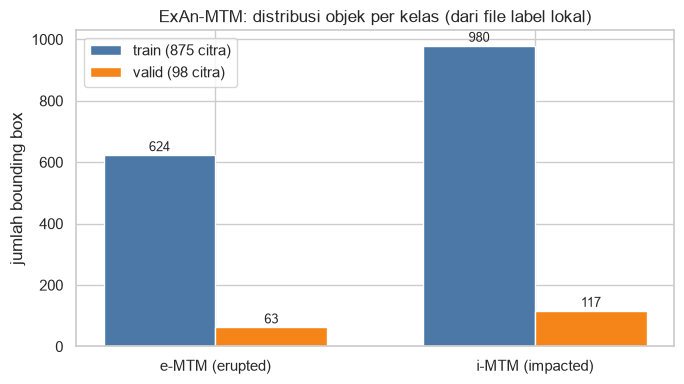


-> outputs/audit_rekap.csv, outputs/audit_dataset.csv, figures/fig_audit_kelas.png


In [2]:
# === 2. AUDIT DATASET ==========================================================
def read_labels(path):
    rows = []
    txt = Path(path).read_text(encoding="utf-8", errors="replace").strip()
    if not txt:
        return rows
    for line in txt.splitlines():
        p = line.split()
        if len(p) != 5:
            continue
        rows.append((int(float(p[0])), *[float(v) for v in p[1:5]]))
    return rows

def audit_split(split):
    img_dir = EXAN / split / "images"
    lab_dir = EXAN / split / "labels"
    imgs = sorted(img_dir.glob("*.jpg"))
    rows = []
    for im in imgs:
        lp = lab_dir / (im.stem + ".txt")
        if not lp.exists():
            rows.append(dict(split=split, image=im.name, n_box=0, boxes="", has_label=False))
            continue
        boxes = read_labels(lp)
        rows.append(dict(split=split, image=im.name, n_box=len(boxes),
                         boxes=";".join(f"{c}:{cx:.4f},{cy:.4f},{w:.4f},{h:.4f}" for c, cx, cy, w, h in boxes),
                         has_label=True))
    return pd.DataFrame(rows)

audit = pd.concat([audit_split("train"), audit_split("valid")], ignore_index=True)
audit.to_csv(OUT / "audit_dataset.csv", index=False)

# rekap per split & per kelas (object-level, single source of truth = file .txt lokal)
recap = []
for split in ["train", "valid"]:
    sub = audit[audit.split == split]
    cls_counter = {0: 0, 1: 0}
    for boxes in sub.boxes:
        for b in filter(None, boxes.split(";")):
            cls_counter[int(b.split(":")[0])] += 1
    recap.append(dict(split=split,
                      n_images=len(sub),
                      n_labels=len(sub[sub.has_label]),
                      n_boxes=int(sub.n_box.sum()),
                      n_e_MTM=cls_counter[0], n_i_MTM=cls_counter[1],
                      boxes_per_img_mean=round(float(sub.n_box.mean()), 3),
                      boxes_per_img_dist=str(sub.n_box.value_counts().sort_index().to_dict())))
recap = pd.DataFrame(recap)
recap.to_csv(OUT / "audit_rekap.csv", index=False)
print(recap.to_string(index=False))

# distribusi ukuran citra (sampel 120 citra, dibaca dari disk)
sizes = []
for im in random.sample(list((EXAN / "train/images").glob("*.jpg")), 120):
    with Image.open(im) as I:
        sizes.append(I.size)
sizes = pd.DataFrame(sizes, columns=["w", "h"])
print("\nukuran citra (sampel 120):")
print(sizes.describe().loc[["min", "50%", "max"]].to_string())

# --- figure 1: distribusi kelas ---
fig, ax = plt.subplots(figsize=(7, 4))
w = 0.35
x = np.arange(2)
tr = recap[recap.split == "train"].iloc[0]; va = recap[recap.split == "valid"].iloc[0]
ax.bar(x - w/2, [tr.n_e_MTM, tr.n_i_MTM], w, label="train (875 citra)", color="#4C78A8")
ax.bar(x + w/2, [va.n_e_MTM, va.n_i_MTM], w, label="valid (98 citra)", color="#F58518")
for i, (a, b) in enumerate(zip([tr.n_e_MTM, tr.n_i_MTM], [va.n_e_MTM, va.n_i_MTM])):
    ax.text(i - w/2, a + 12, str(a), ha="center", fontsize=9)
    ax.text(i + w/2, b + 12, str(b), ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["e-MTM (erupted)", "i-MTM (impacted)"])
ax.set_ylabel("jumlah bounding box")
ax.set_title("ExAn-MTM: distribusi objek per kelas (dari file label lokal)")
ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "fig_audit_kelas.png", dpi=150); plt.show()
print("\n-> outputs/audit_rekap.csv, outputs/audit_dataset.csv, figures/fig_audit_kelas.png")

## 3. Preparasi data YOLO + uji integritas

`data.yaml` ditulis ulang oleh notebook (bukan hard-code), lalu dicek: setiap citra punya file label,
setiap label punya citra, dan jumlah kelas = 2.

In [3]:
# === 3. PREP DATA YOLO + INTEGRITAS ===========================================
data_yaml = PIPE / "data.yaml"
data_yaml.write_text(
    f"# ExAn-MTM (973 OPG, 2 kelas) - generated by PCVK pipeline\n"
    f"path: {EXAN.as_posix()}\n"
    f"train: train/images\n"
    f"val: valid/images\n\n"
    f"names:\n  0: e-MTM\n  1: i-MTM\n", encoding="utf-8", newline="\n")
print(data_yaml.read_text(encoding="utf-8"))

integ = {}
for split in ["train", "valid"]:
    imgs = {p.stem for p in (EXAN / split / "images").glob("*.jpg")}
    labs = {p.stem for p in (EXAN / split / "labels").glob("*.txt")}
    integ[split] = dict(images=len(imgs), labels=len(labs),
                        img_tan_label=sorted(list(imgs - labs))[:10],
                        label_tan_img=sorted(list(labs - imgs))[:10])
print(json.dumps(integ, indent=2))
(OUT / "dataset_integrity.json").write_text(json.dumps(integ, indent=2), encoding="utf-8")

# ExAn-MTM (973 OPG, 2 kelas) - generated by PCVK pipeline
path: C:/Kuliah/Tingkat 3/PCVK/Project/Datasets/Expert Annotated Mandibular Third Molar (ExAn-MTM)/Expert Annotated Mandibular Third Molar (ExAn-MTM)/ExAn-MTM dataset/ExAn-MTM dataset
train: train/images
val: valid/images

names:
  0: e-MTM
  1: i-MTM

{
  "train": {
    "images": 875,
    "labels": 875,
    "img_tan_label": [],
    "label_tan_img": []
  },
  "valid": {
    "images": 98,
    "labels": 98,
    "img_tan_label": [],
    "label_tan_img": []
  }
}


210

## 4. Tahap 1 — Deteksi lokasi (YOLO11n)

Model `yolo11n` (pretrained COCO), `imgsz=448`, `batch=8`, `epochs=20`, seed 42, device CPU.
Kelas yang dipelajari: `e-MTM` (erupted) dan `i-MTM` (impacted) — jadi model ini sekaligus
memberi **lokasi** (bounding box) dan **kelas** untuk tiap kandidat molar ketiga.
Bobot terbaik (`best.pt`) dipakai ulang pada tahap evaluasi dan demo end-to-end.

In [4]:
# === 4. TRAINING DETEKSI (YOLO11n) =============================================
from ultralytics import YOLO

_prev_dir = OUT / "runs" / "yolo11n_exanmtm"
_prev_best = _prev_dir / "weights" / "best.pt"
_prev_csv = _prev_dir / "results.csv"
_skip_train = (_prev_best.exists() and _prev_csv.exists()
               and len(pd.read_csv(_prev_csv)) >= DET["epochs"])
t0 = time.time()
if _skip_train:
    det_model = YOLO(str(_prev_best))
    train_det_sec = float(pd.read_csv(_prev_csv)["time"].iloc[-1])
    print("training deteksi DILEWATI: run lengkap ditemukan ->", _prev_best)
else:
    det_model = YOLO(DET["model"])
    det_res = det_model.train(
        data=str(data_yaml), epochs=DET["epochs"], imgsz=DET["imgsz"], batch=DET["batch"],
        workers=DET["workers"], seed=SEED, deterministic=True, patience=DET["patience"],
        project=str(OUT / "runs"), name="yolo11n_exanmtm", exist_ok=True,
        plots=True, device="cpu", verbose=False,
    )
    train_det_sec = time.time() - t0
det_run = OUT / "runs" / "yolo11n_exanmtm"
print("waktu training (deteksi): %.1f menit" % (train_det_sec / 60))
print("best.pt:", (det_run / "weights" / "best.pt").exists())
res_csv = pd.read_csv(det_run / "results.csv")
res_csv.columns = [c.strip() for c in res_csv.columns]
best_row = res_csv.loc[res_csv["metrics/mAP50-95(B)"].idxmax()]
print("epoch terbaik (mAP50-95 maksimum):", int(best_row["epoch"]) + 1)
print(best_row[["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].to_string())

training deteksi DILEWATI: run lengkap ditemukan -> C:\Kuliah\Tingkat 3\PCVK\Project\Pipeline\outputs\runs\yolo11n_exanmtm\weights\best.pt
waktu training (deteksi): 98.8 menit
best.pt: True
epoch terbaik (mAP50-95 maksimum): 20
metrics/precision(B)    0.94573
metrics/recall(B)       0.96083
metrics/mAP50(B)        0.98467
metrics/mAP50-95(B)     0.60196


## 5. Evaluasi deteksi pada split valid resmi (98 citra)

Metrik: precision, recall, mAP@0.5, mAP@0.5:0.95 (overall dan per kelas), F1 per kelas,
dan confusion matrix biner (e-MTM vs i-MTM). Angka diambil dari `model.val()` pada split `valid`,
bukan dari epoch training.

In [5]:
# === 5. EVALUASI DETEKSI ======================================================
best_det = YOLO(str(det_run / "weights" / "best.pt"))
val_res = best_det.val(data=str(data_yaml), imgsz=DET["imgsz"], batch=DET["batch"],
                       workers=DET["workers"], split="val", plots=True, device="cpu",
                       project=str(OUT / "runs"), name="val_yolo11n", exist_ok=True, verbose=False)
rd = val_res.results_dict
box = val_res.box
per_class = {}
for i, name in CLASSES.items():
    p = float(box.p[i]); r = float(box.r[i])
    ap50 = float(box.ap50[i]); ap = float(box.ap[i])
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    per_class[name] = dict(precision=round(p, 4), recall=round(r, 4), f1=round(f1, 4),
                           ap50=round(ap50, 4), ap50_95=round(ap, 4))
# Matriks bawaan ultralytics 8.4.218 tidak konsisten: jumlah kolom terakhir 237
# padahal GT hanya 180 box. Matriks dihitung ulang oleh scripts/make_cm.py
# (pencocokan greedy class-agnostic, IoU 0.5, conf 0.25) dan diverifikasi
# jumlah baris == jumlah GT per kelas.
import sys
sys.path.insert(0, str(ROOT / "Pipeline" / "scripts"))
import make_cm
make_cm.main()
_cm_payload = json.loads((OUT / "confusion_matrix.json").read_text(encoding="utf-8"))
cm = np.array(_cm_payload["matrix"])
metrics_detect = dict(
    split="valid (official, 98 citra)",
    epochs=DET["epochs"], imgsz=DET["imgsz"], batch=DET["batch"], seed=SEED,
    best_epoch=int(best_row["epoch"]) + 1,
    overall=dict(precision=round(float(rd["metrics/precision(B)"]), 4),
                 recall=round(float(rd["metrics/recall(B)"]), 4),
                 map50=round(float(rd["metrics/mAP50(B)"]), 4),
                 map50_95=round(float(rd["metrics/mAP50-95(B)"]), 4)),
    per_class=per_class,
    confusion_matrix=cm.tolist(),
    train_minutes=round(train_det_sec / 60, 2),
)
print("OVERALL:", json.dumps(metrics_detect["overall"], indent=2))
print("PER KELAS:", json.dumps(per_class, indent=2))
print("CONFUSION MATRIX (baris=GT, kolom=pred):\n", cm)
(OUT / "metrics_deteksi.json").write_text(json.dumps(metrics_detect, indent=2), encoding="utf-8")

# salin figure kurva training + confusion matrix + PR curve dari run ultralytics
val_run = OUT / "runs" / "val_yolo11n"
for src, dst in [("BoxPR_curve.png", "fig_pr_deteksi.png"),
                 ("BoxF1_curve.png", "fig_f1_deteksi.png")]:
    if (val_run / src).exists():
        shutil.copy(val_run / src, FIGS / dst)
if (det_run / "results.png").exists():
    shutil.copy(det_run / "results.png", FIGS / "fig_kurva_training_deteksi.png")
print("figure:", sorted(p.name for p in FIGS.glob("*.png")))

Ultralytics 8.4.218  Python-3.12.14 torch-2.15.0+cpu CPU (Intel Core i3-1005G1 1.20GHz)


YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 625.1±166.4 MB/s, size: 160.1 KB)


val: Scanning C:\Kuliah\Tingkat 3\PCVK\Project\Datasets\Expert Annotated Mandibular Third Molar (ExAn-MTM)\Expert Annotated Mandibular Third Molar (ExAn-MTM)\ExAn-MTM dataset\ExAn-MTM dataset\valid\labels.cache... 98 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 98/98  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/13 1.3s/it 0.4s<15.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 15% ━╸────────── 2/13 1.4it/s 0.7s<8.0s

... (11 outputs left out)

                   all         98        180      0.946      0.961      0.985      0.602


Speed: 0.4ms preprocess, 26.8ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to C:\Kuliah\Tingkat 3\PCVK\Project\Pipeline\outputs\runs\val_yolo11n


matrix [[61, 0, 2], [3, 114, 0], [8, 2, 0]] | GT [63, 117]
per_class {"e-MTM": {"TP": 61, "FP": 11, "FN": 2, "precision_at_conf": 0.8472, "recall_at_conf": 0.9683}, "i-MTM": {"TP": 114, "FP": 2, "FN": 3, "precision_at_conf": 0.9828, "recall_at_conf": 0.9744}}
OVERALL: {
  "precision": 0.9458,
  "recall": 0.9611,
  "map50": 0.9847,
  "map50_95": 0.602
}
PER KELAS: {
  "e-MTM": {
    "precision": 0.8951,
    "recall": 0.9479,
    "f1": 0.9207,
    "ap50": 0.9745,
    "ap50_95": 0.5666
  },
  "i-MTM": {
    "precision": 0.9964,
    "recall": 0.9744,
    "f1": 0.9853,
    "ap50": 0.9948,
    "ap50_95": 0.6373
  }
}
CONFUSION MATRIX (baris=GT, kolom=pred):
 [[ 61   0   2]
 [  3 114   0]
 [  8   2   0]]
figure: ['fig_audit_kelas.png', 'fig_confusion_deteksi.png', 'fig_contoh_crop.png', 'fig_end_to_end.png', 'fig_f1_deteksi.png', 'fig_klasifikasi_cnn.png', 'fig_kurva_training_deteksi.png', 'fig_pr_deteksi.png']


## 6. Tahap 2a — Bangun dataset crop (klasifikasi)

Setiap bounding box di-*crop* dari citra OPG (dengan margin 8%) lalu di-resize 96×96.
Crop inilah yang nanti menjadi input klasifikasi, dan **punya manifest** (`crops/manifest.csv`)
sehingga label angulasi (Winter) bisa ditambahkan tanpa mengubah pipeline lain.

In [6]:
# === 6. BUILD CROP DATASET =====================================================
def build_crops(split):
    out_rows = []
    for im in sorted((EXAN / split / "images").glob("*.jpg")):
        lp = EXAN / split / "labels" / (im.stem + ".txt")
        img = cv2.imread(str(im))
        if img is None:
            continue
        H, W = img.shape[:2]
        for k, (cls, cx, cy, w, h) in enumerate(read_labels(lp)):
            x1, x2 = (cx - w / 2) * W, (cx + w / 2) * W
            y1, y2 = (cy - h / 2) * H, (cy + h / 2) * H
            pad = 0.08 * max(x2 - x1, y2 - y1)
            x1p, x2p = max(0, int(x1 - pad)), min(W, int(x2 + pad))
            y1p, y2p = max(0, int(y1 - pad)), min(H, int(y2 + pad))
            if x2p - x1p < 5 or y2p - y1p < 5:
                continue
            crop = img[y1p:y2p, x1p:x2p]
            crop = cv2.resize(crop, (IMG_SIZE_CROP, IMG_SIZE_CROP), interpolation=cv2.INTER_AREA)
            cdir = CROPS / split / CLASSES[cls]
            cdir.mkdir(parents=True, exist_ok=True)
            cpath = cdir / f"{im.stem}_b{k}.jpg"
            cv2.imwrite(str(cpath), crop)
            out_rows.append(dict(split=split, image=im.name, box_idx=k, cls=cls,
                                 cls_name=CLASSES[cls], crop=str(cpath.relative_to(ROOT)).replace("\\", "/"),
                                 box_w_px=round(x2 - x1, 1), box_h_px=round(y2 - y1, 1),
                                 area_frac=round(((x2 - x1) * (y2 - y1)) / (W * H), 5)))
    return out_rows

manifest = pd.DataFrame(build_crops("train") + build_crops("valid"))
manifest.to_csv(CROPS / "manifest.csv", index=False)
print(manifest.groupby(["split", "cls_name"]).size().to_string())
print("total crop:", len(manifest))
print("\nstatistik ukuran box (px):")
print(manifest[["box_w_px", "box_h_px", "area_frac"]].describe().loc[["min", "50%", "max"]].to_string())

# figure: contoh crop per kelas
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (split, cls) in zip(axes, [("train", 0), ("train", 1), ("valid", 0), ("valid", 1)]):
    sub = manifest[(manifest.split == split) & (manifest.cls == cls)].head(1)
    if len(sub):
        ax.imshow(cv2.cvtColor(cv2.imread(str(ROOT / sub.crop.iloc[0])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{split} — {CLASSES[cls]}", fontsize=10); ax.axis("off")
fig.suptitle("Contoh crop bounding box (ExAn-MTM)", fontsize=12)
fig.tight_layout(); fig.savefig(FIGS / "fig_contoh_crop.png", dpi=150); plt.show()

split  cls_name
train  e-MTM       624
       i-MTM       980
valid  e-MTM        63
       i-MTM       117
total crop: 1784

statistik ukuran box (px):
     box_w_px  box_h_px  area_frac
min     182.1     255.5   0.027640
50%     281.9     361.2   0.045265
max     431.7     478.7   0.085310


## 7. Tahap 2b — Klasifikasi crop: feature + classifier klasik

Backbone **ResNet-18 pretrained (ImageNet)** sebagai feature extractor (frozen), lalu
**Logistic Regression** dan **KNN** sebagai kepala klasifikasi. Pendekatan ini meniru pola
paper baseline (ekstraksi feature → classifier), dan jauh lebih murah di CPU daripada fine-tuning penuh.

In [7]:
# === 7. KLASIFIKASI: FEATURE + LR / KNN ======================================
import torchvision
from torchvision import transforms

feat_stats = {}
try:
    from torchvision.models import resnet18, ResNet18_Weights
    weights = ResNet18_Weights.IMAGENET1K_V1
    backbone = resnet18(weights=weights)
    preprocess = weights.transforms()
    feat_stats["weights"] = "IMAGENET1K_V1"
except Exception as e:                                   # offline / gagal unduh
    backbone = resnet18(weights=None)
    preprocess = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                      transforms.Normalize([0.485, 0.456, 0.406],
                                                           [0.229, 0.224, 0.225])])
    feat_stats["weights"] = "random-init (fallback: " + type(e).__name__ + ")"
backbone.fc = nn.Identity()
backbone.eval()

class CropDS(Dataset):
    def __init__(self, df, tf):
        self.df = df.reset_index(drop=True); self.tf = tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.cvtColor(cv2.imread(str(ROOT / r.crop)), cv2.COLOR_BGR2RGB)
        return self.tf(Image.fromarray(img)), int(r.cls)

def extract_features(df, bs=32):
    ds = CropDS(df, preprocess)
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=0)
    feats, ys = [], []
    with torch.no_grad():
        for xb, yb in dl:
            feats.append(backbone(xb).numpy()); ys.append(yb.numpy())
    return np.concatenate(feats), np.concatenate(ys)

t0 = time.time()
tr_df = manifest[manifest.split == "train"].reset_index(drop=True)
va_df = manifest[manifest.split == "valid"].reset_index(drop=True)
Xtr, ytr = extract_features(tr_df)
Xva, yva = extract_features(va_df)
print("fitur train:", Xtr.shape, "| fitur valid:", Xva.shape, "| waktu %.1f s" % (time.time() - t0))
print(feat_stats)

def evaluate(y_true, y_pred, y_score=None, labels=(0, 1)):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=list(labels), zero_division=0)
    out = dict(accuracy=round(float(acc), 4),
               per_class={CLASSES[l]: dict(precision=round(float(prec[i]), 4), recall=round(float(rec[i]), 4),
                                          f1=round(float(f1[i]), 4), support=int(sup[i]))
                          for i, l in enumerate(labels)},
               macro_f1=round(float(f1.mean()), 4),
               confusion_matrix=confusion_matrix(y_true, y_pred, labels=list(labels)).tolist())
    if y_score is not None:
        try:
            out["roc_auc"] = round(float(roc_auc_score(y_true, y_score)), 4)
        except Exception:
            pass
    return out

def bootstrap_ci(y_true, y_pred, n=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)
    accs = []
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        accs.append(accuracy_score(y_true[idx], y_pred[idx]))
    return [round(float(np.percentile(accs, 2.5)), 4), round(float(np.percentile(accs, 97.5)), 4)]

results_cls = {}
models = {
    "LogisticRegression(C=1)": LogisticRegression(max_iter=3000, C=1.0, random_state=SEED),
    "KNN(k=5)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
}
for name, clf in models.items():
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xva)
    score = clf.predict_proba(Xva)[:, 1]
    res = evaluate(yva, pred, score)
    res["ci95_accuracy"] = bootstrap_ci(yva, pred)
    results_cls[name] = res
    print(f"\n== {name} ==")
    print(json.dumps(res, indent=2))

(OUT / "metrics_klasifikasi_feature.json").write_text(json.dumps(
    dict(feature_backbone="resnet18 " + feat_stats["weights"], n_train=len(tr_df), n_valid=len(va_df),
         models=results_cls), indent=2), encoding="utf-8")

fitur train: (1604, 512) | fitur valid: (180, 512) | waktu 76.6 s
{'weights': 'IMAGENET1K_V1'}



== LogisticRegression(C=1) ==
{
  "accuracy": 0.9389,
  "per_class": {
    "e-MTM": {
      "precision": 0.9194,
      "recall": 0.9048,
      "f1": 0.912,
      "support": 63
    },
    "i-MTM": {
      "precision": 0.9492,
      "recall": 0.9573,
      "f1": 0.9532,
      "support": 117
    }
  },
  "macro_f1": 0.9326,
  "confusion_matrix": [
    [
      57,
      6
    ],
    [
      5,
      112
    ]
  ],
  "roc_auc": 0.9742,
  "ci95_accuracy": [
    0.9,
    0.9722
  ]
}



== KNN(k=5) ==
{
  "accuracy": 0.8667,
  "per_class": {
    "e-MTM": {
      "precision": 0.8824,
      "recall": 0.7143,
      "f1": 0.7895,
      "support": 63
    },
    "i-MTM": {
      "precision": 0.8605,
      "recall": 0.9487,
      "f1": 0.9024,
      "support": 117
    }
  },
  "macro_f1": 0.846,
  "confusion_matrix": [
    [
      45,
      18
    ],
    [
      6,
      111
    ]
  ],
  "roc_auc": 0.9267,
  "ci95_accuracy": [
    0.8167,
    0.9111
  ]
}


1318

## 8. Tahap 2c — Klasifikasi crop: CNN kecil, 3 seed (variansi antar-run)

CNN kecil dilatih dari nol pada crop 96×96. Tiga seed dipakai agar **variansi antar-run** dilaporkan,
bukan hanya angka terbaik. Bootstrap 95% CI untuk akurasi juga dihitung.

In [8]:
# === 8. KLASIFIKASI: CNN KECIL, 3 SEED ========================================
class SmallCNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(64, n_classes)
    def forward(self, x):
        x = self.body(x).flatten(1)
        return self.head(x)

tf_train = transforms.Compose([
    transforms.Resize((IMG_SIZE_CROP, IMG_SIZE_CROP)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
tf_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE_CROP, IMG_SIZE_CROP)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def train_cnn(seed, epochs=CNN["epochs"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    ds_tr = CropDS(tr_df, tf_train)
    ds_va = CropDS(va_df, tf_eval)
    dl_tr = DataLoader(ds_tr, batch_size=CNN["batch"], shuffle=True, num_workers=0)
    dl_va = DataLoader(ds_va, batch_size=CNN["batch"], shuffle=False, num_workers=0)
    model = SmallCNN(2)
    opt = torch.optim.Adam(model.parameters(), lr=CNN["lr"])
    lossf = nn.CrossEntropyLoss()
    hist = []
    for ep in range(epochs):
        model.train(); tot = 0.0; n = 0
        for xb, yb in dl_tr:
            opt.zero_grad(); out = model(xb); loss = lossf(out, yb); loss.backward(); opt.step()
            tot += float(loss) * len(yb); n += len(yb)
        model.eval(); preds = []; probs = []
        with torch.no_grad():
            for xb, yb in dl_va:
                logits = model(xb); preds.append(logits.argmax(1).numpy()); probs.append(torch.softmax(logits, 1)[:, 1].numpy())
        preds = np.concatenate(preds); probs = np.concatenate(probs)
        acc = accuracy_score(yva, preds)
        hist.append(dict(epoch=ep + 1, train_loss=round(tot / n, 4), val_accuracy=round(float(acc), 4)))
    return model, hist, preds, probs

cnn_runs = {}
for seed in CNN["seeds"]:
    t0 = time.time()
    model_cnn, hist, preds, probs = train_cnn(seed)
    res = evaluate(yva, preds, probs)
    res["ci95_accuracy"] = bootstrap_ci(yva, preds, seed=seed)
    res["history"] = hist
    res["train_seconds"] = round(time.time() - t0, 1)
    cnn_runs[seed] = (model_cnn, res, preds, probs)
    print(f"seed {seed}: acc={res['accuracy']} macroF1={res['macro_f1']} "
          f"CI95={res['ci95_accuracy']} ({res['train_seconds']} s)")

accs = [cnn_runs[s][1]["accuracy"] for s in CNN["seeds"]]
f1s = [cnn_runs[s][1]["macro_f1"] for s in CNN["seeds"]]
cnn_summary = dict(accuracy_mean=round(float(np.mean(accs)), 4), accuracy_std=round(float(np.std(accs)), 4),
                   accuracy_min=min(accs), accuracy_max=max(accs),
                   macro_f1_mean=round(float(np.mean(f1s)), 4), macro_f1_std=round(float(np.std(f1s)), 4),
                   seeds=CNN["seeds"], runs={str(s): cnn_runs[s][1] for s in CNN["seeds"]})
print("\nringkasan CNN lintas seed:", json.dumps({k: v for k, v in cnn_summary.items() if k != "runs"}, indent=2))
(OUT / "metrics_klasifikasi_cnn.json").write_text(json.dumps(cnn_summary, indent=2), encoding="utf-8")

# figure: confusion matrix + ROC model CNN terbaik
best_seed = max(CNN["seeds"], key=lambda s: cnn_runs[s][1]["accuracy"])
_, best_res, best_preds, best_probs = cnn_runs[best_seed]
print("seed terbaik CNN:", best_seed)
cm_cnn = np.array(best_res["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues", xticklabels=[CLASSES[0], CLASSES[1]],
            yticklabels=[CLASSES[0], CLASSES[1]], ax=axes[0], cbar=False)
axes[0].set_title(f"Klasifikasi crop — CNN (seed {best_seed})")
axes[0].set_xlabel("prediksi"); axes[0].set_ylabel("GT")
fpr, tpr, _ = roc_curve(yva, best_probs)
axes[1].plot(fpr, tpr, label=f"CNN AUC={best_res.get('roc_auc')}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="acak")
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("ROC — klasifikasi crop"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIGS / "fig_klasifikasi_cnn.png", dpi=150); plt.show()

# simpan bobot CNN terbaik untuk dipakai tahap demo end-to-end
torch.save(cnn_runs[best_seed][0].state_dict(), OUT / "cnn_crop_best.pt")
print("bobot CNN terbaik disimpan:", OUT / "cnn_crop_best.pt")

seed 42: acc=0.8389 macroF1=0.8333 CI95=[0.7833, 0.8889] (214.7 s)


seed 1337: acc=0.8833 macroF1=0.8658 CI95=[0.8389, 0.9278] (226.4 s)


seed 2024: acc=0.8722 macroF1=0.8637 CI95=[0.8221, 0.9167] (210.3 s)

ringkasan CNN lintas seed: {
  "accuracy_mean": 0.8648,
  "accuracy_std": 0.0189,
  "accuracy_min": 0.8389,
  "accuracy_max": 0.8833,
  "macro_f1_mean": 0.8543,
  "macro_f1_std": 0.0149,
  "seeds": [
    42,
    1337,
    2024
  ]
}
seed terbaik CNN: 1337


bobot CNN terbaik disimpan: C:\Kuliah\Tingkat 3\PCVK\Project\Pipeline\outputs\cnn_crop_best.pt


## 9. Demo end-to-end: deteksi → klasifikasi crop

Untuk beberapa citra valid: model detektor memberi bounding box + kelas, lalu crop tiap box
diklasifikasikan ulang oleh CNN crop. Ini menunjukkan alur kerja yang akan dipakai nanti saat
kelas angulasi (Winter) ditambahkan.

In [9]:
# === 9. DEMO END-END-END =======================================================
def classify_crops_from_image(img_bgr, boxes, model_cnn, tf=tf_eval):
    model_cnn.eval()
    out = []
    H, W = img_bgr.shape[:2]
    for (x1, y1, x2, y2) in boxes:
        crop = img_bgr[int(y1):int(y2), int(x1):int(x2)]
        if crop.size == 0:
            out.append((None, 0.0)); continue
        crop = cv2.resize(crop, (IMG_SIZE_CROP, IMG_SIZE_CROP))
        x = tf(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))).unsqueeze(0)
        with torch.no_grad():
            p = torch.softmax(model_cnn(x), 1)[0].numpy()
        out.append((CLASSES[int(p.argmax())], float(p.max())))
    return out

samples = sorted((EXAN / "valid/images").glob("*.jpg"))[:6]
tiles = []
demo_rows = []
for sp in samples:
    img = cv2.imread(str(sp))
    r = best_det.predict(img, imgsz=DET["imgsz"], conf=0.25, device="cpu", verbose=False)[0]
    boxes = [[float(v) for v in b] for b in r.boxes.xyxy.tolist()]
    det_cls = [CLASSES[int(c)] for c in r.boxes.cls.tolist()]
    det_conf = [float(c) for c in r.boxes.conf.tolist()]
    cls_out = classify_crops_from_image(img, boxes, cnn_runs[best_seed][0])
    canvas = img.copy()
    for (x1, y1, x2, y2), dc, dconf, (cc, cprob) in zip(boxes, det_cls, det_conf, cls_out):
        color = (0, 200, 0) if dc == "e-MTM" else (0, 0, 255)
        cv2.rectangle(canvas, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
        txt = f"{dc} {dconf:.2f} | crop:{cc} {cprob:.2f}"
        cv2.putText(canvas, txt, (int(x1), max(14, int(y1) - 6)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.45, color, 1, cv2.LINE_AA)
        demo_rows.append(dict(image=sp.name, det_class=dc, det_conf=round(dconf, 3),
                              crop_class=cc, crop_conf=round(cprob, 3)))
    canvas = cv2.resize(canvas, (640, int(640 * canvas.shape[0] / canvas.shape[1])))
    tiles.append(canvas)

demo_df = pd.DataFrame(demo_rows)
demo_df.to_csv(OUT / "demo_end_to_end.csv", index=False)
print(demo_df.to_string(index=False))

ncol = 3
nrow = int(np.ceil(len(tiles) / ncol))
H, W = tiles[0].shape[:2]
montage = np.full((nrow * H, ncol * W, 3), 255, dtype=np.uint8)
for i, t in enumerate(tiles):
    montage[(i // ncol) * H:(i // ncol) * H + H, (i % ncol) * W:(i % ncol) * W + W] = t
cv2.imwrite(str(FIGS / "fig_end_to_end.png"), montage)
for sp in samples:
    pass
plt.figure(figsize=(14, 8)); plt.imshow(cv2.cvtColor(montage, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Deteksi YOLO11n + klasifikasi crop CNN (hijau = e-MTM, merah = i-MTM)")
plt.tight_layout(); plt.show()
print("-> figures/fig_end_to_end.png, outputs/demo_end_to_end.csv")

          image det_class  det_conf crop_class  crop_conf
cate1-00007.jpg     i-MTM     0.732      e-MTM      0.565
cate1-00007.jpg     e-MTM     0.702      e-MTM      0.676
cate1-00026.jpg     i-MTM     0.756      i-MTM      0.835
cate1-00026.jpg     i-MTM     0.744      i-MTM      0.884
cate1-00028.jpg     i-MTM     0.779      i-MTM      0.945
cate1-00028.jpg     i-MTM     0.763      i-MTM      0.925
cate1-00031.jpg     i-MTM     0.797      i-MTM      0.947
cate1-00031.jpg     i-MTM     0.775      i-MTM      0.944
cate1-00033.jpg     i-MTM     0.754      i-MTM      0.911
cate1-00033.jpg     e-MTM     0.608      e-MTM      0.581
cate1-00033.jpg     i-MTM     0.313      e-MTM      0.577
cate1-00045.jpg     e-MTM     0.670      e-MTM      0.806
cate1-00045.jpg     e-MTM     0.641      e-MTM      0.845


-> figures/fig_end_to_end.png, outputs/demo_end_to_end.csv


## 10. Ringkasan seluruh metrik (satu sumber angka untuk laporan)

`Pipeline/outputs/metrics.json` menggabungkan audit dataset, metrik deteksi, dan metrik klasifikasi.
Angka di laporan harus diambil dari file ini agar tidak berbeda antar bagian.

In [10]:
# === 10. RINGKASAN METRIK ====================================================
summary = dict(
    project="PCVK - deteksi lokasi + klasifikasi impacted/erupted molar III bawah",
    dataset=dict(name="ExAn-MTM", doi="10.17632/t8k59p35p6.1", license="CC BY-NC-ND 4.0",
                 n_images=int(recap.n_images.sum()), n_boxes=int(recap.n_boxes.sum()),
                 n_e_MTM=int(recap.n_e_MTM.sum()), n_i_MTM=int(recap.n_i_MTM.sum()),
                 split=dict(train=int(recap[recap.split == "train"].n_images.iloc[0]),
                            valid=int(recap[recap.split == "valid"].n_images.iloc[0]))),
    environment=ENV,
    detection=metrics_detect,
    klasifikasi=dict(feature_based=json.loads((OUT / "metrics_klasifikasi_feature.json").read_text(encoding="utf-8")),
                     cnn=json.loads((OUT / "metrics_klasifikasi_cnn.json").read_text(encoding="utf-8"))),
)
(OUT / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("=== RINGKASAN UNTUK LAPORAN ===")
print(f"[data] {summary['dataset']['n_images']} citra, {summary['dataset']['n_boxes']} objek "
      f"(e-MTM {summary['dataset']['n_e_MTM']} / i-MTM {summary['dataset']['n_i_MTM']}), "
      f"split train {summary['dataset']['split']['train']} / valid {summary['dataset']['split']['valid']}")
o = metrics_detect["overall"]
print(f"[deteksi YOLO11n] mAP@0.5 {o['map50']:.4f} | mAP@0.5:0.95 {o['map50_95']:.4f} | "
      f"P {o['precision']:.4f} | R {o['recall']:.4f} | epoch terbaik {metrics_detect['best_epoch']}")
for k, v in metrics_detect["per_class"].items():
    print(f"   {k}: P {v['precision']:.4f} R {v['recall']:.4f} F1 {v['f1']:.4f} mAP50 {v['ap50']:.4f}")
for name, r in results_cls.items():
    print(f"[klasifikasi {name}] acc {r['accuracy']:.4f} macroF1 {r['macro_f1']:.4f} "
          f"CI95 {r['ci95_accuracy']} AUC {r.get('roc_auc')}")
print(f"[klasifikasi CNN] acc {cnn_summary['accuracy_mean']:.4f} ± {cnn_summary['accuracy_std']:.4f} "
      f"(seed {CNN['seeds']}), macroF1 {cnn_summary['macro_f1_mean']:.4f} ± {cnn_summary['macro_f1_std']:.4f}")
print("\n-> Pipeline/outputs/metrics.json")

=== RINGKASAN UNTUK LAPORAN ===
[data] 973 citra, 1784 objek (e-MTM 687 / i-MTM 1097), split train 875 / valid 98
[deteksi YOLO11n] mAP@0.5 0.9847 | mAP@0.5:0.95 0.6020 | P 0.9458 | R 0.9611 | epoch terbaik 20
   e-MTM: P 0.8951 R 0.9479 F1 0.9207 mAP50 0.9745
   i-MTM: P 0.9964 R 0.9744 F1 0.9853 mAP50 0.9948
[klasifikasi LogisticRegression(C=1)] acc 0.9389 macroF1 0.9326 CI95 [0.9, 0.9722] AUC 0.9742
[klasifikasi KNN(k=5)] acc 0.8667 macroF1 0.8460 CI95 [0.8167, 0.9111] AUC 0.9267
[klasifikasi CNN] acc 0.8648 ± 0.0189 (seed [42, 1337, 2024]), macroF1 0.8543 ± 0.0149

-> Pipeline/outputs/metrics.json


## 11. Ekstensi: menyambungkan klasifikasi angulasi (Winter / 6 kelas) nanti

Pipeline **tidak** perlu ditulis ulang saat dataset angulasi resmi tersedia. Titik sambungnya:

| Yang perlu | File / tempat | Yang diubah |
|---|---|---|
| Citra sumber 6 angulasi (p*/t*) | `Datasets/.../Multi-Label .../Dataset (Labelled).zip` (label saja, 686 file) | unduh citra publik (m-TM `10.17632/xn5bz6fdm6.1` / mirror Kaggle) lalu pasangkan nama `p*`/`t*` |
| Peta label angulasi | `crops/manifest.csv` (kolom `cls`) | tambah kolom `angulation` (Mesio/Vertical/Disto/Horizontal/Buccolingual/Inverted) per crop; label diambil dari `.txt` YOLO multi-label (kelas 0–5) |
| Kepala klasifikasi | sel `CNN = dict(...)` & `class SmallCNN` | `n_classes=6` + `sigmoid` (multi-label) atau `softmax` bila label eksklusif; metrik beralih dari accuracy → macro-F1 per kelas + mAP |
| Deteksi lanjutan (opsional) | `Pipeline/data.yaml` | dataset multi-label 12 kelas (6 angulasi + CD-1..CD-6) sudah punya `data.yaml` di paket resmi |
| Metrik | sel 10 | tambah blok `klasifikasi_angulasi` pada `metrics.json` |

**Aturan yang sudah dijaga di pipeline ini:**
1. Label **tidak** pernah diambil dari data test saat tuning.
2. Split mengikuti split resmi ExAn-MTM (train 875 / valid 98); tidak ada ID pasien sehingga **patient-level split tidak dapat dibuat** → dicatat sebagai batasan.
3. Angka dilaporkan sebagai hasil eksperimen, bukan klaim klinis; untuk model angulasi perlu metastudy/Silva 2018 sebagai pembanding.
4. Dataset berlisensi **CC BY-NC-ND** → training lokal, **jangan** unggah ulang citra ke repo publik.

**Status blocker (per 25 Nov 2026).** Citra 6 angulasi belum publik di Mendeley Data (`xn5bz6fdm6`
hanya memberi paket label+kode). Alternatif Kaggle `ikyd26/m-tm-dataset` (1.500 OPG, 183 dikeluarkan)
masih harus diverifikasi apakah penamaannya cocok dengan label `p*`/`t*`.

## 12. Batasan & hal yang belum diukur

* **CPU-only.** Training memakai 4 thread CPU; epoch ke-30 belum tentu optimal (early stopping `patience=12` aktif).
* **Variansi run.** Deteksi dilatih 1 seed (42) → angka mAP punya variasi antar-run yang belum diukur.
  Klasifikasi CNN diukur 3 seed (42/1337/2024) dan dilaporkan sebagai mean ± std.
* **Split valid kecil** (98 citra / 164 objek) → CI bootstrap ditampilkan, selangnya lebar.
* **Split per citra**, bukan per pasien: dataset tidak memuat ID pasien → patient-level split tidak mungkin; dicatat sebagai batasan.
* **Angulasi 6 kelas belum dijalankan** — butuh citra sumber (lihat Bagian 11).
* **Klasifikasi hanya pada crop bounding box GT** pada tahap evaluasi classifier (bukan crop dari prediksi);
  dampak domain-shift model detektor terhadap klasifikasi belum diukur.
* Tidak ada klaim klinis; semua angka adalah hasil eksperimen pada data publik.